# Khảo sát dữ liệu House Prices

In [1]:
from pathlib import Path
import sys

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
sys.path.insert(0, str(project))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.evaluation import DATA, RESULTS, SEED, load_data, make_folds, save_submission
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
figures = RESULTS / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Cấu trúc dữ liệu

In [2]:
print("Train:", train.shape, "| Test:", test.shape)
print("Dòng trùng:", train.duplicated().sum())
display(train.head())

Train: (1460, 81) | Test: (1459, 80)
Dòng trùng: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Nhận xét về cấu trúc dữ liệu

- Tập train có **1.460 dòng và 81 cột**. Tập test có **1.459 dòng và 80 cột**. Tập train có thêm cột `SalePrice`, là giá bán dùng làm biến mục tiêu. Mô hình sẽ dự đoán giá bán cho từng căn nhà trong tập test.
- Kết quả `train.duplicated().sum()` bằng **0**, tức là không có dòng nào trùng hoàn toàn khi xét tất cả các cột, kể cả `Id`.
- Năm dòng đầu cho thấy dữ liệu có cả biến số như `LotArea` và biến phân loại như `MSZoning`. Một số giá trị ở cột `Alley` hiển thị `NaN`. Ý nghĩa của các giá trị này sẽ được đối chiếu với `data_description.txt` ở phần khảo sát dữ liệu thiếu.

## 2. Phân phối giá

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

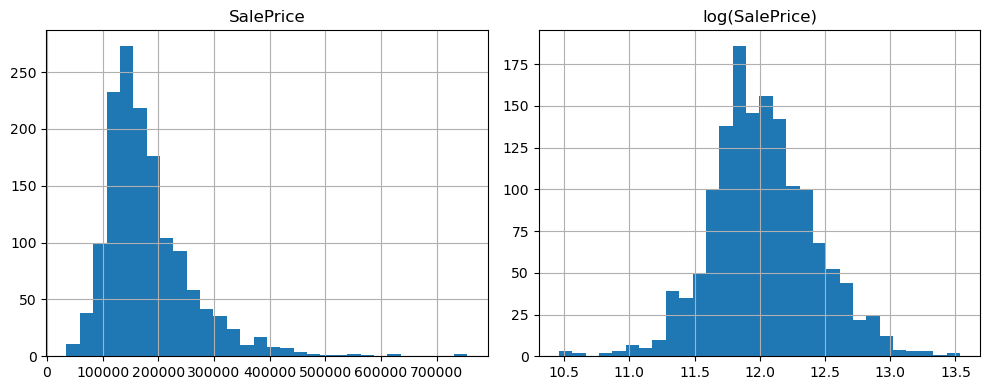

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train["SalePrice"].hist(ax=axes[0], bins=30)
np.log(train["SalePrice"]).hist(ax=axes[1], bins=30)
axes[0].set_title("SalePrice")
axes[1].set_title("log(SalePrice)")
fig.tight_layout()
fig.savefig(figures / "sale_price.png", dpi=160)
plt.show()


### Nhận xét về phân phối giá nhà

- Phân phối `SalePrice`: Giá nhà có xu hướng lệch phải rõ rệt. Phần lớn các căn nhà có giá tập trung trong khoảng 100.000 – 200.000 USD, trong khi một số căn có giá trên 400.000 USD, khiến phần đuôi phân phối kéo dài về bên phải.
- Giá trị ngoại lệ: Biểu đồ cho thấy một số căn nhà có giá rất cao, lên đến khoảng 750.000 USD. Đây là những giá trị có khả năng bất thường so với phần lớn dữ liệu và cần được xem xét trong quá trình phân tích.
- Phân phối `log(SalePrice)`: Sau khi áp dụng phép biến đổi logarit tự nhiên, phân phối trở nên cân đối hơn và có hình dạng gần với phân phối chuẩn. Phần lớn giá trị tập trung trong khoảng 11,5 – 12,5, cho thấy mức độ lệch phải đã giảm đáng kể.
- Ý nghĩa đối với mô hình: Phép biến đổi logarit giúp giảm ảnh hưởng của các giá trị giá nhà quá cao và ổn định hơn sự biến thiên của biến mục tiêu. Vì vậy, có thể sử dụng `log(SalePrice)` trong quá trình huấn luyện để hỗ trợ cải thiện khả năng dự đoán.
- Kết luận: Biến `SalePrice` có phân phối lệch phải, trong khi `log(SalePrice)` có phân phối cân đối hơn. Do đó, ưu tiên thử nghiệm biến mục tiêu `log(SalePrice)` khi xây dựng mô hình dự đoán giá nhà và đánh giá hiệu quả bằng kết quả thực nghiệm.


## 3. Dữ liệu thiếu

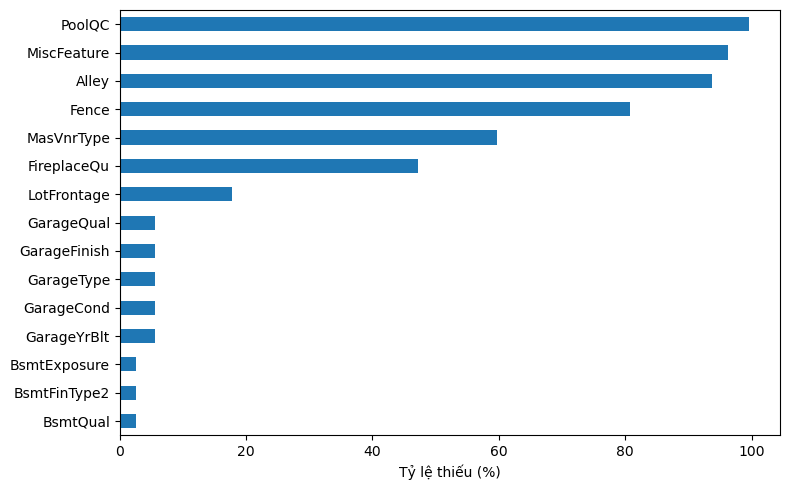

In [5]:
missing = train.isna().mean().mul(100).sort_values(ascending=False)
ax = missing[missing.gt(0)].head(15).sort_values().plot.barh(figsize=(8, 5))
ax.set_xlabel("Tỷ lệ thiếu (%)")
ax.figure.tight_layout()
ax.figure.savefig(figures / "missing_values.png", dpi=160)
plt.show()


### Nhận xét về dữ liệu thiếu

- Các thuộc tính `PoolQC`, `MiscFeature` và `Alley` có tỷ lệ thiếu rất cao, trên 90%. Tiếp theo là `Fence` và `MasVnrType`, với tỷ lệ thiếu lần lượt khoảng 80% và 60%.
- Một số giá trị thiếu không hẳn do lỗi dữ liệu mà có thể phản ánh đặc điểm của căn nhà. Ví dụ, giá trị thiếu ở `PoolQC` có thể cho biết căn nhà không có hồ bơi.
- Thuộc tính `LotFrontage` có tỷ lệ thiếu khoảng 18%, cần được xử lý vì đây là thông tin liên quan đến diện tích mặt tiền tiếp giáp đường.
- Các thuộc tính liên quan đến garage và basement có tỷ lệ thiếu thấp, nhưng vẫn cần xử lý trước khi huấn luyện mô hình.

**Kết luận:** Bộ dữ liệu có nhiều thuộc tính chứa giá trị thiếu với tỷ lệ khác nhau. Nhóm sẽ xử lý giá trị thiếu dựa trên loại dữ liệu và ý nghĩa của từng thuộc tính, nhằm hạn chế mất thông tin trước khi huấn luyện mô hình.

## 4. Quan hệ với giá 

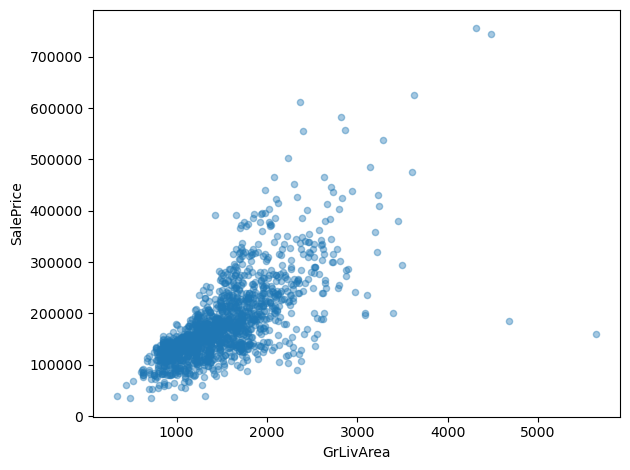

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

In [6]:
ax = train.plot.scatter(x="GrLivArea", y="SalePrice", alpha=0.4)
ax.figure.tight_layout()
ax.figure.savefig(figures / "area_vs_price.png", dpi=160)
plt.show()
display(train.drop(columns="Id").corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False).head(10))




### Nhận xét về mối quan hệ giữa diện tích và giá bán

- Biểu đồ phân tán cho thấy diện tích nhà (`GrLivArea`) có mối tương quan tỉ lệ thuận với giá bán (`SalePrice`). Nhìn chung, diện tích nhà càng lớn thì giá bán càng cao.
- Phần lớn dữ liệu tập trung ở nhóm nhà có diện tích và giá bán ở mức thấp đến trung bình. Một số căn nhà có diện tích lớn nhưng giá bán thấp xuất hiện như những điểm ngoại lệ.

**Kết luận:** Diện tích nhà có mối liên hệ đáng kể với giá bán, do đó đây là một thuộc tính cần được chú ý trong quá trình xây dựng mô hình dự đoán giá nhà.



## 5. kiểm tra cấu trúc train/ test

### Kiểm tra số dòng, số cột và Id trùng

In [7]:
dataset_summary = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Test"],
    "Số dòng": [len(train), len(test)],
    "Số cột": [train.shape[1], test.shape[1]],
    "Số Id trùng": [
        train["Id"].duplicated().sum(),
        test["Id"].duplicated().sum(),
    ],
})

display(dataset_summary)

,Tập dữ liệu,Số dòng,Số cột,Số Id trùng
0,Train,1460,81,0
1,Test,1459,80,0


**Nhận xét:** Số `Id` trùng bằng 0 trong cả tập train và tập test. Như vậy, mỗi căn nhà có mã `Id` duy nhất trong từng tập. Có thể dùng `Id` để ghép giá dự đoán với từng căn nhà trong file nộp Kaggle.

### So sánh tên cột, kiểu dữ liệu giữa train và test

In [8]:
# Id là mã định danh, SalePrice là biến mục tiêu.
train_features = train.drop(columns=["Id", "SalePrice"])
test_features = test.drop(columns=["Id"])

train_columns = set(train_features.columns)
test_columns = set(test_features.columns)

print("Cột chỉ có ở train:", sorted(train_columns - test_columns))
print("Cột chỉ có ở test:", sorted(test_columns - train_columns))

# So sánh kiểu dữ liệu của các cột xuất hiện trong cả hai tập.
common_columns = sorted(train_columns & test_columns)
dtype_comparison = pd.DataFrame({
    "Train": train_features[common_columns].dtypes.astype(str),
    "Test": test_features[common_columns].dtypes.astype(str),
})

different_types = dtype_comparison["Train"] != dtype_comparison["Test"]
print("Các cột có kiểu dữ liệu khác nhau:")
display(dtype_comparison.loc[different_types])

Cột chỉ có ở train: []
Cột chỉ có ở test: []
Các cột có kiểu dữ liệu khác nhau:


,Train,Test
BsmtFinSF1,int64,float64
BsmtFinSF2,int64,float64
BsmtFullBath,int64,float64
BsmtHalfBath,int64,float64
BsmtUnfSF,int64,float64
GarageArea,int64,float64
GarageCars,int64,float64
TotalBsmtSF,int64,float64


**Nhận xét:** Sau khi bỏ cột `Id` và biến mục tiêu `SalePrice`, tập train và test có cùng 79 cột đầu vào. Không có cột đầu vào nào chỉ xuất hiện ở một tập.

Có 8 cột liên quan đến tầng hầm và gara, chẳng hạn `TotalBsmtSF`, `GarageArea` và `GarageCars`, được đọc dưới dạng `int64` ở train và `float64` ở test. Sự khác biệt này có thể do tập test chứa giá trị thiếu (`NaN`) trong các cột đó. Cả hai kiểu đều là kiểu số, nên nhóm sẽ kiểm tra giá trị thiếu ở mục 7 để chọn cách xử lý phù hợp.

### Đếm cột theo kiểu lưu trữ và xem mã loại nhà

In [9]:
numeric_features = train_features.select_dtypes(include="number")
other_features = train_features.select_dtypes(exclude="number")

print("Số cột được lưu dưới dạng số:", numeric_features.shape[1])
print("Số cột được lưu dưới dạng khác:", other_features.shape[1])

print("Số căn theo mã loại nhà MSSubClass:")
house_type_counts = train["MSSubClass"].value_counts().sort_index()
display(house_type_counts.to_frame("Số căn nhà"))

Số cột được lưu dưới dạng số: 36
Số cột được lưu dưới dạng khác: 43
Số căn theo mã loại nhà MSSubClass:


,Số căn nhà
MSSubClass,
20,536
30,69
40,4
45,12
50,144
60,299
70,60
75,16
80,58


**Nhận xét:** Trong 79 cột đầu vào của tập train, 36 cột được lưu dưới dạng số và 43 cột được lưu dưới dạng khác.

`MSSubClass` được lưu bằng số nhưng biểu diễn mã loại nhà. Số căn phân bố không đều giữa các mã. Mã `20` có nhiều nhất với 536 căn, tiếp theo là mã `60` với 299 căn, còn mã `40` chỉ có 4 căn.

Khi xây dựng mô hình, nhóm có thể thử mã hóa `MSSubClass` như một biến phân loại vì độ lớn và khoảng cách giữa các mã không thể hiện mức chênh lệch giữa các loại nhà.

## 6. so sánh giá gốc và log giá

In [10]:
price_scales = pd.DataFrame({
    "SalePrice": train["SalePrice"],
    "log(SalePrice)": np.log(train["SalePrice"]),
})

price_summary = price_scales.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).T
price_summary["skewness"] = price_scales.skew()
display(price_summary.round(3))

,count,mean,std,min,10%,25%,50%,75%,90%,max,skewness
SalePrice,1460.0,180921.196,79442.503,34900.00,106475.000,129975.000,163000.000,214000.000,278000.000,755000.000,1.883
log(SalePrice),1460.0,12.024,0.399,10.46,11.576,11.775,12.002,12.274,12.535,13.534,0.121



### Nhận xét về giá gốc và giá sau biến đổi logarit

- Giá bán trung bình: Biến `SalePrice` có giá trị trung bình khoảng 180.921 USD, cao hơn trung vị 163.000 USD. Điều này cho thấy một số căn nhà có giá bán cao đã kéo giá trị trung bình tăng lên.
- Khoảng giá bán: Giá nhà thấp nhất là 34.900 USD, cao nhất là 755.000 USD. Khoảng chênh lệch lớn cho thấy giá bán giữa các căn nhà có sự khác biệt đáng kể.
- Phân bố giá nhà: Có 50% số căn nhà có giá bán nằm trong khoảng 129.975 – 214.000 USD*. Ngoài ra, 90% số căn nhà có giá không vượt quá 278.000 USD, cho thấy phần lớn dữ liệu tập trung ở nhóm giá thấp và trung bình.
- Độ lệch phân phối: Biến `SalePrice` có độ lệch 1,883, thể hiện phân phối lệch phải rõ rệt. Sau khi biến đổi logarit, độ lệch giảm xuống còn 0,121, cho thấy phân phối trở nên cân đối hơn và gần với phân phối chuẩn.
- Độ phân tán: Độ lệch chuẩn của `SalePrice` là khoảng 79.443 USD, trong khi `log(SalePrice)` có độ lệch chuẩn 0,399. Phép biến đổi logarit giúp thu hẹp khoảng cách giữa các giá trị lớn và nhỏ trên thang đo logarit.

**Kết luận:** Phép biến đổi `log(SalePrice)` làm giảm đáng kể độ lệch phải của dữ liệu và hạn chế ảnh hưởng của các giá bán quá cao. Vì vậy, nhóm lựa chọn thử nghiệm `log(SalePrice)` làm biến mục tiêu trong quá trình huấn luyện mô hình nhằm cải thiện khả năng dự đoán và giảm tác động của các giá trị cực lớn.


## 7. so sánh dữ liệu thiếu giữa train và test

,Train (%),Test (%),Tỷ lệ thiếu cao nhất (%)
PoolQC,99.52,99.79,99.79
MiscFeature,96.30,96.50,96.50
Alley,93.77,92.67,93.77
Fence,80.75,80.12,80.75
MasVnrType,59.73,61.27,61.27
FireplaceQu,47.26,50.03,50.03
LotFrontage,17.74,15.56,17.74
GarageFinish,5.55,5.35,5.55
GarageType,5.55,5.21,5.55
GarageQual,5.55,5.35,5.55


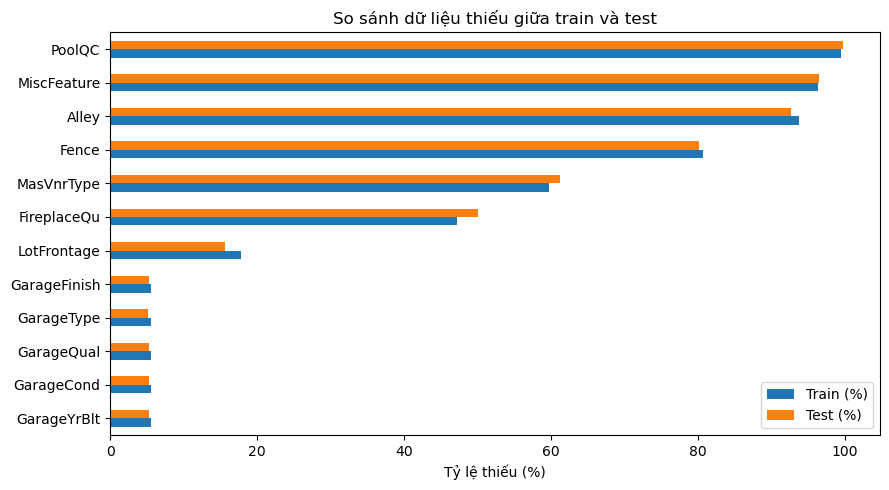

Một số dòng train thiếu GarageType:


,GarageType,GarageFinish,GarageCars,GarageArea
39,NaN,NaN,0,0
48,NaN,NaN,0,0
78,NaN,NaN,0,0
88,NaN,NaN,0,0
89,NaN,NaN,0,0
99,NaN,NaN,0,0
108,NaN,NaN,0,0
125,NaN,NaN,0,0
127,NaN,NaN,0,0
140,NaN,NaN,0,0


In [11]:
missing_comparison = pd.DataFrame({
    "Train (%)": train.drop(columns=["Id", "SalePrice"]).isna().mean() * 100,
    "Test (%)": test.drop(columns="Id").isna().mean() * 100,
})

missing_comparison["Tỷ lệ thiếu cao nhất (%)"] = missing_comparison.max(axis=1)
missing_comparison = (
    missing_comparison.loc[missing_comparison["Tỷ lệ thiếu cao nhất (%)"] > 0]
    .sort_values("Tỷ lệ thiếu cao nhất (%)", ascending=False)
)
display(missing_comparison.round(2))

top_missing = missing_comparison.head(12)[["Train (%)", "Test (%)"]]
if not top_missing.empty:
    ax = top_missing.iloc[::-1].plot.barh(figsize=(9, 5))
    ax.set_xlabel("Tỷ lệ thiếu (%)")
    ax.set_title("So sánh dữ liệu thiếu giữa train và test")
    ax.figure.tight_layout()
    ax.figure.savefig(figures / "missing_train_vs_test.png", dpi=160)
    plt.show()

garage_columns = ["GarageType", "GarageFinish", "GarageCars", "GarageArea"]
print("Một số dòng train thiếu GarageType:")
display(train.loc[train["GarageType"].isna(), garage_columns].head(10))

### Nhận xét:

- Kết quả cho thấy dữ liệu Train và Test có tỷ lệ giá trị thiếu tương đối giống nhau ở phần lớn các thuộc tính. Trong đó, `PoolQC` có tỷ lệ thiếu cao nhất, khoảng 99,5% ở Train và 99,79% ở Test. Tiếp theo là `MiscFeature` (trên 96%), `Alley` (trên 92%) và `Fence` (khoảng 80%). Điều này cho thấy một số thuộc tính có rất ít dữ liệu được ghi nhận.

- Các thuộc tính như `MasVnrType` và `FireplaceQu` cũng có tỷ lệ thiếu đáng kể, dao động khoảng 47–61%. Trong khi đó, nhóm thuộc tính liên quan đến gara như `GarageType`, `GarageFinish`, `GarageQual` và `GarageCond` có tỷ lệ thiếu khoảng 5%, với mức chênh lệch nhỏ giữa hai tập dữ liệu.

- Đối với các dòng thiếu `GarageType`, kết quả kiểm tra cho thấy `GarageCars` và `GarageArea` đều bằng 0. Điều này cho thấy các giá trị thiếu ở nhóm thuộc tính gara có thể xuất phát từ việc ngôi nhà không có gara, thay vì lỗi thu thập dữ liệu.

**Kết luận:** Nhìn chung, dữ liệu Train và Test có đặc điểm thiếu dữ liệu khá tương đồng. Vì vậy, cần xử lý giá trị thiếu phù hợp với ý nghĩa của từng thuộc tính, chẳng hạn sử dụng giá trị "None" cho các thuộc tính thể hiện sự không tồn tại của một tiện ích, thay vì loại bỏ toàn bộ các dòng có dữ liệu thiếu.